# 7000LBSBAI - Programming for Business Analytics
## Week 6 - Task: Your First Complete EDA
### 📋 ANSWER VERSION: for checking coding and independent study

---

**Module:** Programming for Business Analytics  
**Week:** 6  
**Time:** About 75 minutes, plus optional extensions  
**Topics covered:** The EDA workflow · Loading and inspecting · Cleaning · Describing · Distributions · Relationships · Summarising findings

---

### How to use this notebook

| Symbol | Meaning |
|--------|---------|
| ✍️ Worked example | Code is already written -> run it and study the output |
| ➡️ Your turn | Write or complete the code in this cell |
| 💬 What does it mean? | Write a short interpretation of your results |
| 🔴 Extension | For students who finish early (optional) |
| 📝 Hint/Tip | Some friendly help and advice |

To run a cell: click on it and press **Shift + Enter**.

---

## ⚠️ BEFORE YOU CONTINUE

### Save a copy of this notebook

Make sure your notebook is saved to your Google Drive:
- **File → Save a copy in Drive**
- Name it: `Week6_Task_EDA_SwiftDeliver_YourName.ipynb`

---
## The scenario

**SwiftDeliver** is a food delivery company. The operations manager has sent you **400 recent orders** and asked one question:

> ### *"What affects delivery times and customer ratings?"*

| Column | What it holds |
|--------|---------------|
| `order_id` | A unique ID for each order |
| `order_date` | The date of the order |
| `restaurant_type` | Pizza, Burger, Asian, Healthy or Dessert |
| `distance_km` | Distance from the restaurant to the customer (km) |
| `weather` | Dry or Rain |
| `driver_experience_yrs` | How many years the driver has worked for SwiftDeliver |
| `delivery_time_mins` | Time from order to delivery (minutes) |
| `order_value` | Value of the order (£) |
| `tip` | Tip given to the driver (£) |
| `rating` | The customer's rating, from 1 (worst) to 5 (best) |

---
## The EDA workflow

Exploratory data analysis follows the same stages every time, and you have focused on a different  stage each week. **This notebook is an EDA workbook**: each section is one stage.

| Section | Stage | Week | Suggested time |
|---|---|---|---|
| 0 | The question and the data | | 5 min |
| 1 | Load and inspect | 2 | 5 min |
| 2 | Clean: Spot → Fix → Check | 3 | 15 min |
| 3 | Describe | 4 | 10 min |
| 4 | Visualise distributions | 5 | 10 min |
| 5 | Relationships | 6 | 15 min |
| 6 | Summarise your findings | | 15 min |

### ✅ The EDA checklist

Use this checklist for your EDA:

- The business question is written down
- The data is loaded and inspected
- Problems are spotted, fixed and checked, with a record of what you changed and why
- The key variables are described with statistics
- Their distributions are visualised and described
- Relationships between variables are explored
- Findings, limitations and next steps are summarised in plain English

> 📝 Most cells are empty: write the code yourself. The hints say which week covers each skill, so you can look back at your earlier notebooks.

---
# Section 0: The question and the data
*From Week 6* · **Purpose:** be clear about what you are trying to find out before you start.

### ✏️ 0.1 The business question

- In your own words, what does the operations manager want to know?
- Which **two or three columns** do you expect to matter most, and why?

**MODEL ANSWER:**

The manager wants to know **what makes deliveries slower or faster**, and **what makes customers give higher or lower ratings**. The most important columns are likely to be `delivery_time_mins` and `rating` (the two things we are trying to explain), and `distance_km` and `weather` (which seem likely to affect delivery time). `driver_experience_yrs` might also matter.

---
# Section 1: Load and inspect
*From Week 2* · **Purpose:** get the data in and see what it looks like.

In [ ]:
# ➡️ 1.1 Import pandas, NumPy, matplotlib and seaborn, set the seaborn theme, and load the data
url = "https://raw.githubusercontent.com/7000lbsbai/7000LBSBAI/main/datasets/swiftdeliver_orders.csv"

# Write your code below this line
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_csv(url)
print(f"Data loaded: {df.shape[0]} rows and {df.shape[1]} columns")

# ✅ 408 rows and 10 columns

Data loaded: 408 rows and 10 columns


In [ ]:
# ➡️ 1.2 Show the first 5 rows, then the column names, data types and non-null counts
display(df.head())
df.info()

# ✅ rating has 395 non-null values out of 408: some ratings are missing
# 📝 display() shows a table nicely when it is not the last line of a cell

,order_id,order_date,restaurant_type,distance_km,weather,driver_experience_yrs,delivery_time_mins,order_value,tip,rating
0,SD0001,2024-09-21,Asian,3.6,Rain,8,32,48.95,3.64,3.0
1,SD0002,2024-09-16,Burger,2.6,Dry,4,20,18.09,0.38,4.0
2,SD0003,2024-09-08,dessert,1.9,Dry,3,20,6.59,0.00,5.0
3,SD0004,2024-09-25,Asian,4.4,Rain,1,36,23.20,2.21,3.0
4,SD0005,2024-09-10,Dessert,4.4,Dry,7,27,49.58,3.54,4.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               408 non-null    object 
 1   order_date             408 non-null    object 
 2   restaurant_type        408 non-null    object 
 3   distance_km            408 non-null    float64
 4   weather                408 non-null    object 
 5   driver_experience_yrs  408 non-null    int64  
 6   delivery_time_mins     408 non-null    int64  
 7   order_value            408 non-null    float64
 8   tip                    408 non-null    float64
 9   rating                 395 non-null    float64
dtypes: float64(4), int64(2), object(4)
memory usage: 32.0+ KB


---
# Section 2: Clean: Spot → Fix → Check
*From Week 3* · **Purpose:** make sure the data can be trusted before analysing it.

In [ ]:
# ➡️ 2.1 Spot: print the missing values, the number of duplicates, the restaurant_type values, and the smallest delivery time
print(df.isnull().sum())
print()
print(f"Duplicate rows: {df.duplicated().sum()}")
print()
print(df['restaurant_type'].value_counts())
print()
print(f"Shortest delivery time: {df['delivery_time_mins'].min()} minutes")

# ✅ 13 missing ratings, 8 duplicates, 21 different spellings of 5 restaurant types,
#    and a delivery time of 0 minutes, which is impossible

order_id                  0
order_date                0
restaurant_type           0
distance_km               0
weather                   0
driver_experience_yrs     0
delivery_time_mins        0
order_value               0
tip                       0
rating                   13
dtype: int64

Duplicate rows: 8

restaurant_type
Pizza       107
Burger      105
Asian        89
Healthy      41
Dessert      31
Asian         4
Burger        3
Pizza         3
pizza         3
 Asian        3
Healthy       3
dessert       2
 Pizza        2
ASIAN         2
Dessert       2
 Burger       2
burger        2
BURGER        1
HEALTHY       1
 Dessert      1
healthy       1
Name: count, dtype: int64

Shortest delivery time: 0 minutes


> 📝 **Hint:** Week 3. Use `print()` for each check so that they all show.

In [ ]:
# ➡️ 2.2 Fix: remove the duplicates, tidy the restaurant_type names, and remove the impossible delivery time

# Remove duplcate rows
df = df.drop_duplicates()

# Check they have been removed
print(f"Duplicate rows: {df.duplicated().sum()}")


Duplicate rows: 0


In [ ]:
# Tidy the values in the 'restaurant_type' column
df['restaurant_type'] = df['restaurant_type'].str.strip().str.title()

# Check the values in the 'restaurant_type' column have been updated
print(df['restaurant_type'].value_counts())


restaurant_type
Pizza      113
Burger     110
Asian       96
Healthy     45
Dessert     36
Name: count, dtype: int64


In [ ]:
# Remove the impossible delivery times=0
df = df[df['delivery_time_mins'] > 0]

# Check the delivery times=0 have been removed
print(f"Shortest delivery time: {df['delivery_time_mins'].min()} minutes")


Shortest delivery time: 10 minutes


### ➡️ 2.3 What about the missing ratings?

Ratings are missing when a customer **did not leave one**. You could **fill** them, **drop** those orders, or **keep** them as they are.

> 📝 pandas **skips** missing values when it calculates a mean, a median or a correlation.

Decide what to do, write the code if you need any, and explain your decision in a `#` comment.

In [ ]:
# ➡️ 2.3 Your decision about the missing ratings
# Keep them. A missing rating means the customer did not leave one, so filling it
# (e.g. with the median) would invent ratings nobody gave, and dropping those orders
# would lose their delivery times, distances and order values, which are still useful.
# pandas skips missing values in means and correlations, so no code is needed.

In [ ]:
# ➡️ 2.4 Check: print the shape, the number of duplicates, the number of restaurant types, and the smallest delivery time
print(f"Shape: {df.shape}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Restaurant types: {df['restaurant_type'].nunique()}")
print(f"Shortest delivery time: {df['delivery_time_mins'].min()} minutes")

# ✅ (399, 10), 0 duplicates, 5 restaurant types, shortest delivery 10 minutes

Shape: (399, 10)
Duplicate rows: 0
Restaurant types: 5
Shortest delivery time: 10 minutes


### ✏️ 2.5 Your cleaning log

- List each change you made to the data, and why. (Your Assessment 2 notebook needs one of these.)

**MODEL ANSWER:**

- **Removed 8 duplicate rows** (408 to 400): the same orders recorded twice would be counted twice.
- **Tidied `restaurant_type`** with `.str.strip().str.title()`: 21 spellings became 5 types.
- **Removed 1 order with a delivery time of 0 minutes**: impossible, so almost certainly an error (400 to 399).
- **Kept the 12 missing ratings**: customers chose not to rate, and the rest of each order is still useful. pandas skips them in calculations.

Final dataset: **399 orders**.

---
# Section 3: Describe
*From Week 4* · **Purpose:** summarise the key variables with statistics.

In [ ]:
# ➡️ 3.1 Print the mean, median, standard deviation, minimum and maximum of delivery_time_mins
t = df['delivery_time_mins']
print(f"Mean:    {t.mean():.1f} minutes")
print(f"Median:  {t.median():.1f} minutes")
print(f"Std:     {t.std():.1f} minutes")
print(f"Range:   {t.min()} to {t.max()} minutes")

# ✅ Mean 26.2, median 24.0, std 9.2, range 10 to 63

Mean:    26.2 minutes
Median:  24.0 minutes
Std:     9.2 minutes
Range:   10 to 63 minutes


In [ ]:
# ➡️ 3.2 For each restaurant_type, show the count, mean and median delivery time, rounded to 1 decimal place
df.groupby('restaurant_type')['delivery_time_mins'].agg(['count', 'mean', 'median']).round(1)

# ✅ Medians are all between 23 and 25 minutes: restaurant type makes little difference

,count,mean,median
restaurant_type,,,
Asian,96,25.9,24.5
Burger,110,25.0,23.0
Dessert,36,26.3,25.0
Healthy,45,26.9,25.0
Pizza,112,27.2,25.0


> 📝 **Hint:** Week 4, `groupby` with `.agg()`.

In [ ]:
# ➡️ 3.3 For each weather type, show the mean delivery time and the mean rating, rounded to 2 decimal places
df.groupby('weather')[['delivery_time_mins', 'rating']].mean().round(2)

# ✅ Rain: deliveries about 7 minutes slower on average, and ratings lower

,delivery_time_mins,rating
weather,,
Dry,23.96,3.92
Rain,31.38,3.43


> 📝 **Hint:** to summarise two columns at once, select them with double brackets: `[['col1', 'col2']]`.

### 💬 What does it mean?

- What is a typical delivery time?
- Does the type of restaurant or the weather make more difference to delivery times?

**✏️ MODEL ANSWER:**

A typical delivery takes about **24 minutes** (median); the mean (26.2) is a little higher, so a few slow deliveries pull it up. **Restaurant type makes very little difference** (medians between 23 and 25 minutes), but **weather makes a big one**: deliveries in the rain take about **7 minutes longer** on average (31.4 against 24.0 minutes), and rain-day orders get lower ratings (3.43 against 3.92).

---
# Section 4: Visualise distributions
*From Week 5* · **Purpose:** see the shape of the key variables.

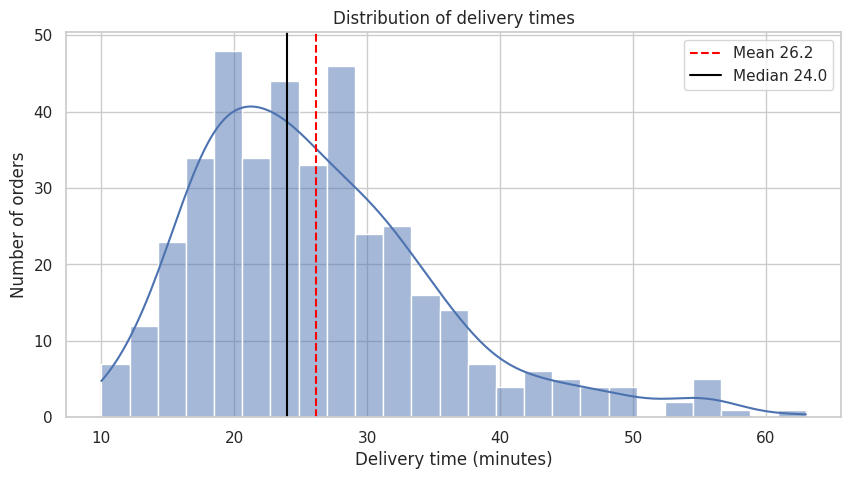

Skew: 1.10


In [ ]:
# ➡️ 4.1 A histogram of delivery_time_mins with a density curve, the mean and median marked, a title and axis labels. Print the skew.
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='delivery_time_mins', bins=25, kde=True)
plt.axvline(df['delivery_time_mins'].mean(), color='red', linestyle='--', label=f"Mean {df['delivery_time_mins'].mean():.1f}")
plt.axvline(df['delivery_time_mins'].median(), color='black', label=f"Median {df['delivery_time_mins'].median():.1f}")
plt.title('Distribution of delivery times')
plt.xlabel('Delivery time (minutes)')
plt.ylabel('Number of orders')
plt.legend()
plt.show()

print(f"Skew: {df['delivery_time_mins'].skew():.2f}")

# ✅ Skew 1.10: right-skewed

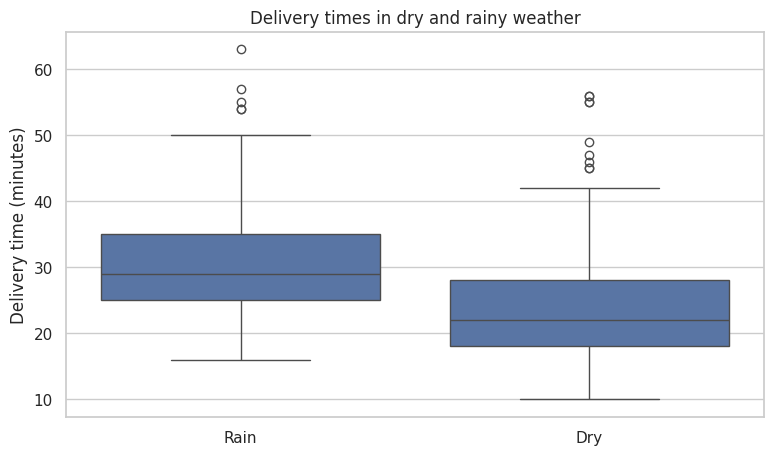

In [ ]:
# ➡️ 4.2 A boxplot of delivery_time_mins for each weather type, with a title and axis labels
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='weather', y='delivery_time_mins')
plt.title('Delivery times in dry and rainy weather')
plt.xlabel('')
plt.ylabel('Delivery time (minutes)')
plt.show()

> 📝 **Hint:** Week 5, Blocks 1 and 2.

### 💬 What does it mean?

- What shape is the distribution of delivery times? What does that mean for which average to report?
- How do delivery times compare in dry and rainy weather?

**✏️ MODEL ANSWER:**

Delivery times are **right-skewed** (skew 1.10): most deliveries take between about 19 and 31 minutes, with a tail of slow deliveries up to 63 minutes. So the **median (24 minutes)** is the better summary of a typical delivery. The boxplot shows that **rain shifts the whole distribution upwards**: the median rises from 22 to 29 minutes, and rainy days have more of the very slow deliveries.

---
# Section 5: Relationships
*From Week 6* · **Purpose:** find out which variables are related to delivery time and rating.

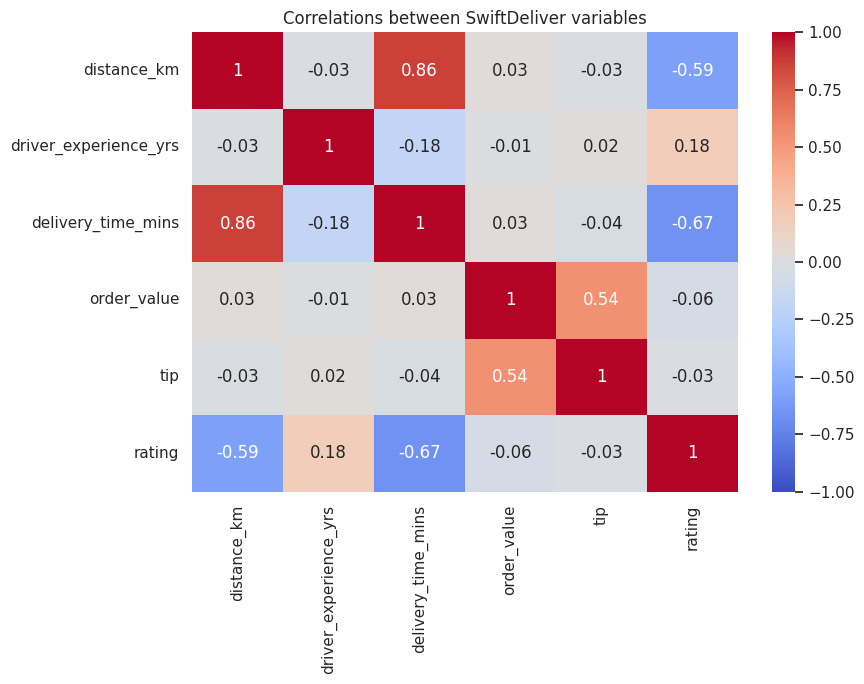

In [ ]:
# ➡️ 5.1 A correlation heatmap of the numeric columns: distance_km, driver_experience_yrs, delivery_time_mins, order_value, tip and rating
cols = ['distance_km', 'driver_experience_yrs', 'delivery_time_mins', 'order_value', 'tip', 'rating']
corr = df[cols].corr().round(2)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations between SwiftDeliver variables')
plt.tight_layout()
plt.show()

# ✅ distance and delivery time 0.86; delivery time and rating -0.67; order value and tip 0.54

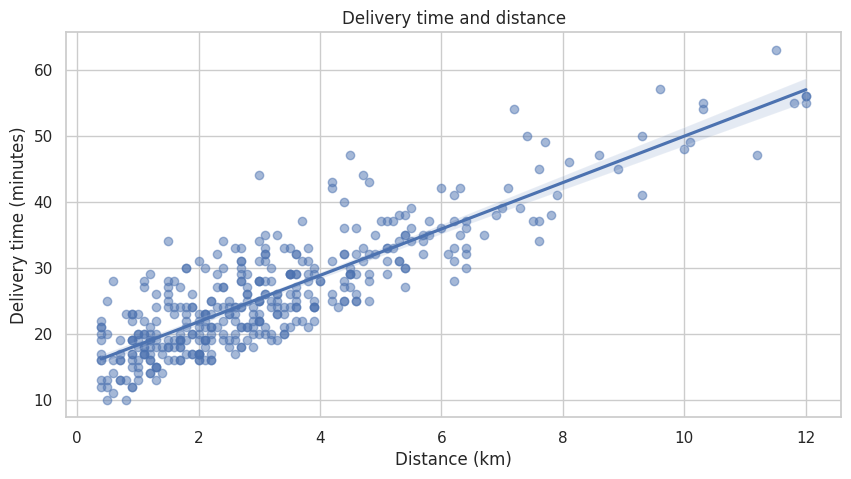

Correlation (r): 0.86


In [ ]:
# ➡️ 5.2 A scatter plot with a trend line of distance_km and delivery_time_mins, with a title and axis labels. Print the correlation.
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='distance_km', y='delivery_time_mins', scatter_kws={'alpha': 0.5})
plt.title('Delivery time and distance')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery time (minutes)')
plt.show()

print(f"Correlation (r): {df['distance_km'].corr(df['delivery_time_mins']):.2f}")

# ✅ r = 0.86

> 📝 The shaded band is the **95% confidence interval** for the trend line. Here it is very narrow, because there are lots of orders and they follow the line closely: we can be confident about the relationship between distance and delivery time.

### ➡️ 5.3 Delivery time and rating: choose the chart

`rating` only takes five values (1 to 5), so a scatter plot puts the points in five overlapping lines. **Which chart from Week 5** would show how delivery time differs across the five ratings more clearly? Create it, and print the correlation between delivery time and rating.

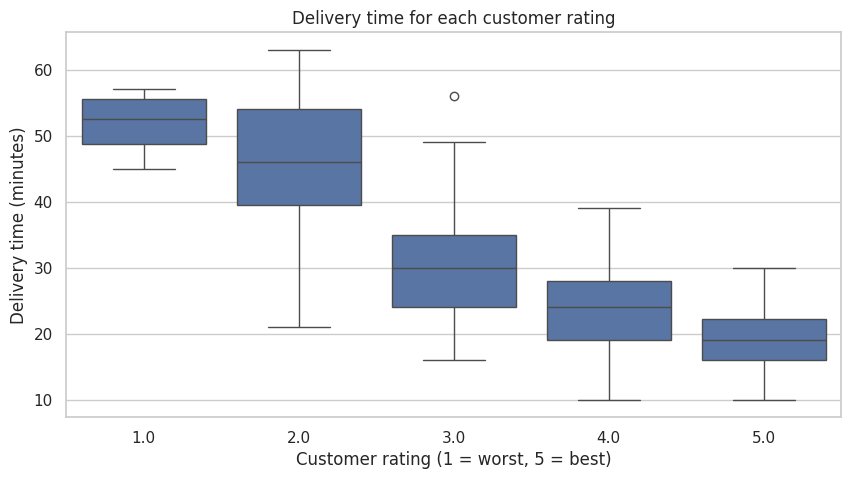

Correlation (r): -0.67


In [ ]:
# ➡️ 5.3 Your chart of delivery time and rating, and the correlation
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='rating', y='delivery_time_mins')
plt.title('Delivery time for each customer rating')
plt.xlabel('Customer rating (1 = worst, 5 = best)')
plt.ylabel('Delivery time (minutes)')
plt.show()

print(f"Correlation (r): {df['delivery_time_mins'].corr(df['rating']):.2f}")

# ✅ A boxplot with one box per rating; r = -0.67

### 💬 What does it mean?

- Which variables are most strongly related to delivery time, and to rating?
- Describe the relationship between delivery time and rating: direction and strength.
- Can you say that slow deliveries cause low ratings? Why or why not?

**✏️ MODEL ANSWER:**

**Distance** is very strongly related to delivery time (*r* = 0.86): longer journeys take longer, as expected. **Delivery time** has a **strong negative** relationship with rating (*r* = −0.67): the boxplot shows the median delivery time falling steadily from **52.5 minutes** for 1-star orders to **19 minutes** for 5-star orders. Driver experience has only a **weak** link with delivery time (−0.18), and order value is related to tips (0.54) but not to rating. The 95% confidence interval around the distance trend line is very narrow, so we can be confident in this relationship: it is based on almost 400 orders that follow the line closely. It is very **plausible** that slow deliveries lead to low ratings, but correlation alone does not prove it: for example, long-distance and rainy-day orders are both slower, and something else about those orders could also affect ratings.

---
# Section 6: Summarise your findings
*From Week 6* · **Purpose:** answer the business question in plain English.

### ✏️ 6.1 Key findings

- Write **three key findings** that answer the manager's question. Use numbers from your analysis.

**MODEL ANSWER:**

1. **Distance is the biggest driver of delivery time** (*r* = 0.86). A typical delivery takes 24 minutes, but long-distance orders take much longer.
2. **Rain adds about 7 minutes** to the median delivery time (29 against 22 minutes), while the type of restaurant makes very little difference.
3. **Slower deliveries get lower ratings** (*r* = −0.67): 5-star orders took a median of 19 minutes, 1-star orders 52.5 minutes.

### ✏️ 6.2 Limitations

- What are the **limitations** of this analysis? Think about the data and the methods.

**MODEL ANSWER:**

- **Correlation is not causation**: we cannot be sure slow deliveries *cause* low ratings.
- **12 ratings are missing**, and customers who choose not to rate may differ from those who do.
- The data covers **only four weeks** in September, so it may not reflect other seasons (for example, winter weather).
- Some useful information is **not in the data**, such as the time of day, traffic or how busy the restaurant was.

### ✏️ 6.3 Next steps and recommendations

- What would you **recommend** to the manager, and what would you **analyse next**?

**MODEL ANSWER:**

**Recommendations:** set realistic delivery estimates for long distances and rainy days, and consider extra drivers when rain is forecast, since faster deliveries are linked to better ratings.

**Next steps:** look at delivery time and rating together **within** dry and rainy days, to check that the link holds in both; and collect data on time of day and traffic to explain more of the variation.

---
## 🔴 Extension 1: save a chart for a report

Choose your best chart from this notebook, make it report-ready, and save it with `plt.savefig()` (before `plt.show()`). Then download it from the **Files** panel: click the folder icon, find the file, click the three dots and choose **Download**.

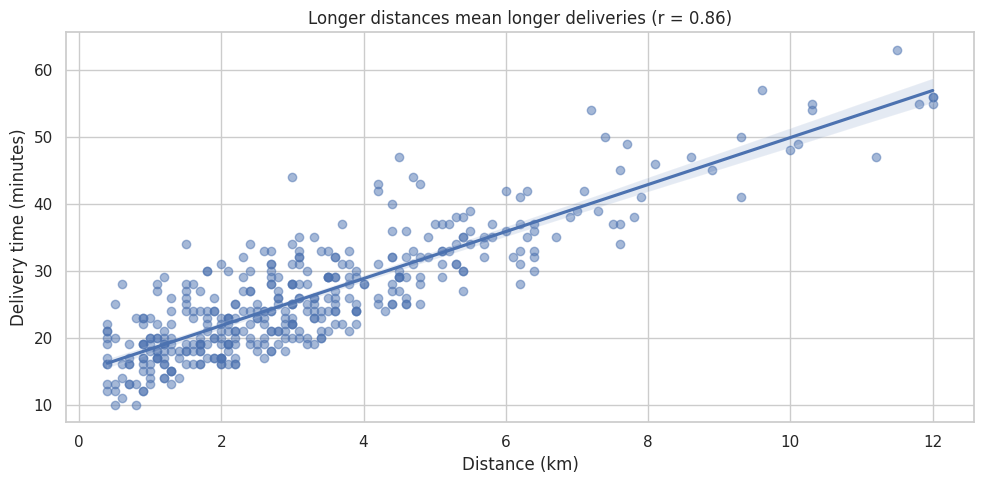

In [ ]:
# 🔴 Extension 1: a report-ready chart, saved
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='distance_km', y='delivery_time_mins', scatter_kws={'alpha': 0.5})
plt.title('Longer distances mean longer deliveries (r = 0.86)')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery time (minutes)')
plt.tight_layout()
plt.savefig('delivery_time_and_distance.png', dpi=150)
plt.show()

---
## 🔴 Extension 2: does driver experience help?

Draw a scatter plot with a trend line of `driver_experience_yrs` and `delivery_time_mins`, and print the correlation. How strong is the relationship?

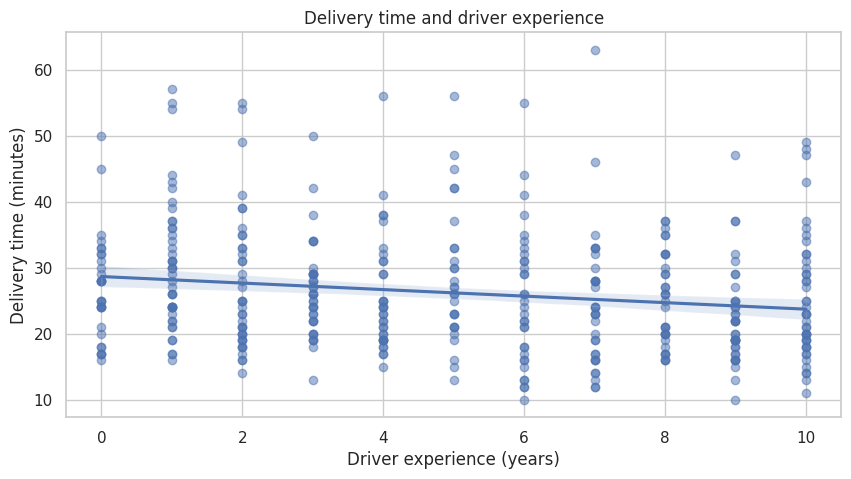

Correlation (r): -0.18


In [ ]:
# 🔴 Extension 2: driver experience and delivery time
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='driver_experience_yrs', y='delivery_time_mins', scatter_kws={'alpha': 0.5})
plt.title('Delivery time and driver experience')
plt.xlabel('Driver experience (years)')
plt.ylabel('Delivery time (minutes)')
plt.show()

print(f"Correlation (r): {df['driver_experience_yrs'].corr(df['delivery_time_mins']):.2f}")

# ✅ r = -0.18: a weak negative relationship. More experienced drivers are slightly faster,
#    but distance and weather matter far more

---
## 🔴 Extension 3: what affects tips?

Explore the `tip` column. How is it related to order value? What percentage of orders have **no tip** at all?

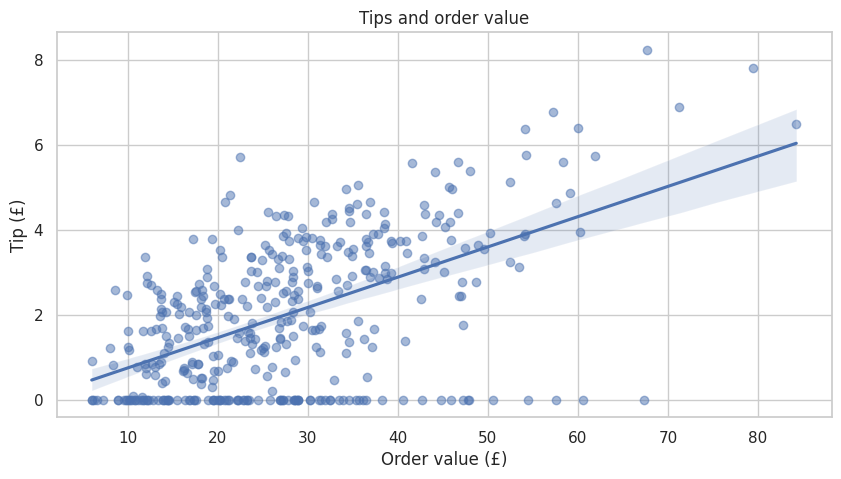

Correlation (r): 0.54
Orders with no tip: 25.1%


In [ ]:
# 🔴 Extension 3: tips
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='order_value', y='tip', scatter_kws={'alpha': 0.5})
plt.title('Tips and order value')
plt.xlabel('Order value (£)')
plt.ylabel('Tip (£)')
plt.show()

print(f"Correlation (r): {df['order_value'].corr(df['tip']):.2f}")
print(f"Orders with no tip: {(df['tip'] == 0).mean() * 100:.1f}%")

# ✅ r = 0.54: bigger orders get bigger tips. The line of points along the bottom
#    shows the orders with no tip

---
## ✅ End of Task: Recap

You have completed a **full exploratory data analysis**, using every stage you have learned:

| Section | Stage | Week |
|---|---|---|
| 1 | Load and inspect | 2 |
| 2 | Clean: Spot → Fix → Check, with a cleaning log | 3 |
| 3 | Describe with statistics and `groupby` | 4 |
| 4 | Visualise distributions | 5 |
| 5 | Explore relationships | 6 |
| 6 | Summarise findings, limitations and next steps | |

**Keep this notebook.** Its structure, and the EDA checklist at the top, is exactly what your Assessment 2 notebook needs.

---

### 💾 Before you leave

Make sure your notebook is saved to your Google Drive, if you have not done so already:
- **File → Save a copy in Drive**
- Name it: `Week6_Task_EDA_SwiftDeliver_YourName.ipynb`

---

### 🔮 After reading week

Week 7 is Directed Study week week. In Week 8 we take a more advanced approach to EDA and start preparing for **Assessment 2**.